# EDA e baseline — triagem de laudos médicos

**Autor:** Alessandro Stefani  
**Data:** 2026-10-18  
**Disciplina:** Tech Challenge Fase 03 — Cloud e MLOps  
**Aula:** Bloco 0 — EDA e baseline  
**Descrição:** conhecer o Medical Abstracts TC Corpus, definir como separar treino e validação e
estabelecer o baseline (TF-IDF + Regressão Logística) que os próximos modelos precisam superar.

## 1. Setup

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline

SEED = 42
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DIR_RAW = RAIZ / "data" / "raw"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 2. Carga e schema

In [2]:
treino = pd.read_csv(DIR_RAW / "medical_tc_train.csv")
teste = pd.read_csv(DIR_RAW / "medical_tc_test.csv")
NOMES = dict(pd.read_csv(DIR_RAW / "medical_tc_labels.csv").values)
ORDEM = sorted(NOMES)

print(f"treino: {treino.shape} | teste: {teste.shape}")
display(pd.Series(NOMES, name="condição").rename_axis("rótulo").to_frame())
display(treino.head(3))

treino: (11550, 2) | teste: (2888, 2)


,condição
rótulo,
1,neoplasms
2,digestive system diseases
3,nervous system diseases
4,cardiovascular diseases
5,general pathological conditions


,condition_label,medical_abstract
0,5,Tissue changes around loose prostheses. A canine model to investigate the effects of an antiinflammatory agent. The ...
1,1,Neuropeptide Y and neuron-specific enolase levels in benign and malignant pheochromocytomas. Neuron-specific enolase...
2,2,"Sexually transmitted diseases of the colon, rectum, and anus. The challenge of the nineties. During the past two dec..."


In [ ]:
def checar_schema(df: pd.DataFrame, nome: str) -> pd.Series:
    texto = df["medical_abstract"]
    return pd.Series(
        {
            "linhas": len(df),
            "texto nulo ou vazio": int((texto.fillna("").str.strip() == "").sum()),
            "rótulo nulo": int(df["condition_label"].isna().sum()),
            "rótulo fora de 1 a 5": int((~df["condition_label"].isin(ORDEM)).sum()),
        },
        name=nome,
    )


display(pd.concat([checar_schema(treino, "treino"), checar_schema(teste, "teste")], axis=1))

Nenhum texto vazio ou rótulo inválido.

## 3. Distribuição das classes

,treino_n,teste_n,treino_%,teste_%
condition_label,,,,
neoplasms,2530,633,21.9,21.9
digestive system diseases,1195,299,10.3,10.4
nervous system diseases,1540,385,13.3,13.3
cardiovascular diseases,2441,610,21.1,21.1
general pathological conditions,3844,961,33.3,33.3


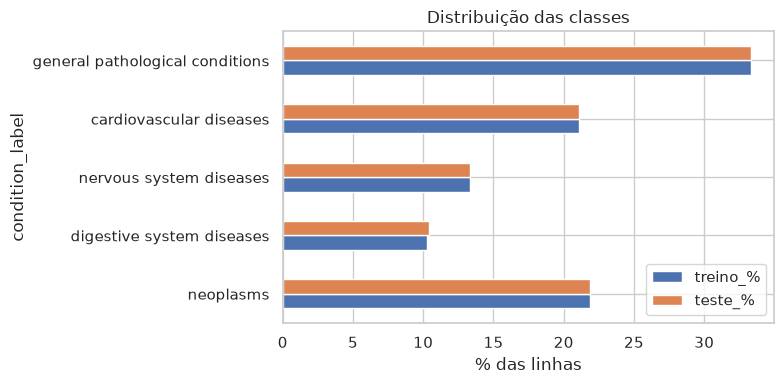

In [3]:
dist = pd.DataFrame(
    {
        "treino_n": treino["condition_label"].value_counts().sort_index(),
        "teste_n": teste["condition_label"].value_counts().sort_index(),
    }
)
for col in ["treino", "teste"]:
    dist[f"{col}_%"] = (dist[f"{col}_n"] / dist[f"{col}_n"].sum() * 100).round(1)
dist.index = dist.index.map(NOMES)
display(dist)

ax = dist[["treino_%", "teste_%"]].plot.barh(figsize=(8, 4))
ax.set_xlabel("% das linhas")
ax.set_title("Distribuição das classes")
plt.tight_layout()
plt.show()

*General pathological conditions* tem ~3× mais linhas que *digestive system diseases*. A acurácia seria dominada pela classe maior, então usaremos **F1-macro** como métrica principal, assim as 5 classes tem mesmo peso.

## 4. Tamanho dos textos

,palavras
count,11550.0
mean,180.0
std,76.0
min,24.0
50%,175.0
90%,275.0
95%,302.0
99%,382.0
max,596.0


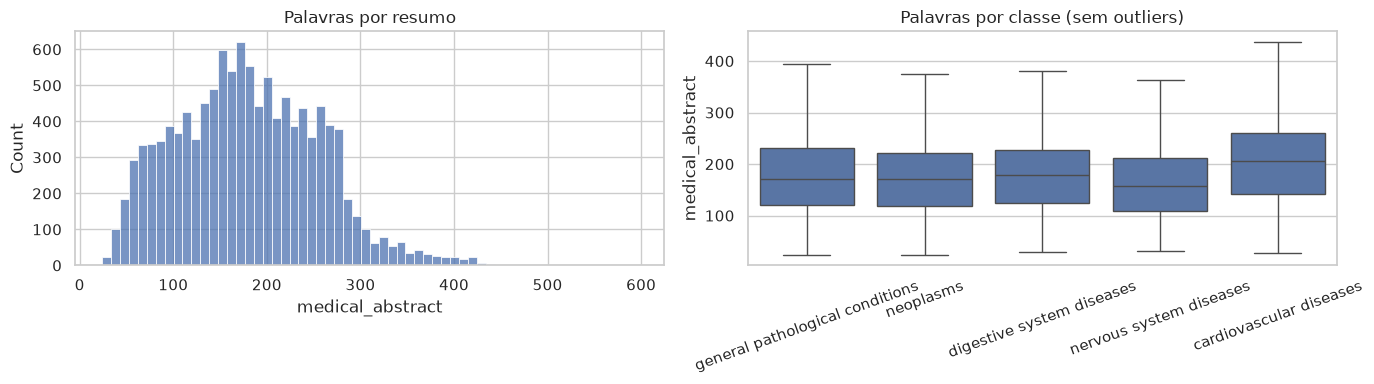

In [4]:
n_palavras = treino["medical_abstract"].str.split().str.len()
display(n_palavras.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0).to_frame("palavras"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(n_palavras, bins=60, ax=axes[0])
axes[0].set_title("Palavras por resumo")
sns.boxplot(x=treino["condition_label"].map(NOMES), y=n_palavras, ax=axes[1], showfliers=False)
axes[1].set_title("Palavras por classe (sem outliers)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Mediana de ~175 palavras e cauda com até 596.

## 5. Duplicatas: o dataset é multirrótulo

Avaliação de textos repetidos dentro do treino e entre treino e teste, após normalização.

In [7]:
def normalizar(textos: pd.Series) -> pd.Series:
    return textos.str.lower().str.split().str.join(" ")


treino["texto_norm"] = normalizar(treino["medical_abstract"])
teste["texto_norm"] = normalizar(teste["medical_abstract"])
conjuntos = treino.groupby("texto_norm")["condition_label"].agg(frozenset)  # condições de cada resumo

pares_treino = set(zip(treino["texto_norm"], treino["condition_label"]))
texto_no_treino = teste["texto_norm"].isin(set(treino["texto_norm"]))
mesmo_par = sum((t, r) in pares_treino for t, r in zip(teste["texto_norm"], teste["condition_label"]))

display(
    pd.Series(
        {
            "Linhas do treino": len(treino),
            "Resumos únicos no treino": treino["texto_norm"].nunique(),
            "Pares (texto, rótulo) repetidos no treino": int(
                treino.duplicated(["texto_norm", "condition_label"]).sum()
            ),
            "Linhas do teste cujo texto está no treino": int(texto_no_treino.sum()),
            "Linhas do teste cujo texto está no treino com o mesmo rótulo": mesmo_par,
        },
        name="contagem",
    ).to_frame()
)
display(conjuntos.map(len).value_counts().sort_index().rename_axis("condições por resumo").to_frame("resumos"))

,contagem
Linhas do treino,11550
Resumos únicos no treino,9445
"Pares (texto, rótulo) repetidos no treino",0
Linhas do teste cujo texto está no treino,1010
Linhas do teste cujo texto está no treino com o mesmo rótulo,0


,resumos
condições por resumo,
1,7489
2,1810
3,143
4,3


In [8]:
exemplo = conjuntos[conjuntos.map(len) == 3].index[0]
display(
    treino.loc[treino["texto_norm"] == exemplo, ["condition_label", "medical_abstract"]].assign(
        condição=lambda d: d["condition_label"].map(NOMES)
    )
)

,condition_label,medical_abstract,condição
3987,3,'Locked-in syndrome' for 27 years following a viral illness: clinical and pathologic findings. We describe a man who...,nervous system diseases
8424,5,'Locked-in syndrome' for 27 years following a viral illness: clinical and pathologic findings. We describe a man who...,general pathological conditions
10457,1,'Locked-in syndrome' for 27 years following a viral illness: clinical and pathologic findings. We describe a man who...,neoplasms


**Nenhum par (texto, rótulo) se repete**. Um resumo sobre com N classes possui N linhas (uma por classe), causando:

1. **Máximo de um acerto por texto**, quando ele possui mais de uma classe.
2. Linhas do teste cujo texto está no treino aparecem lá sempre com **outro rótulo**.
3. Split de validação **agrupado por texto**, para não termos o mexmo texto em grupos diferentes.
4. Verificação de **acerto por texto como**. A classe prevista está entre as condições do resumo?

## 6. A classe *general pathological conditions*

In [5]:
for i, texto in enumerate(
    treino.loc[treino["condition_label"] == 5, "medical_abstract"].sample(3, random_state=SEED), 1
):
    print(f"--- exemplo {i} ---\n{texto[:600]}...\n")

--- exemplo 1 ---
Dorsal root ganglionectomy for failed back surgery syndrome: a 5-year follow-up study. Dorsal root ganglionectomy has been suggested as a method for the treatment of chronic intractable radicular pain, with theoretical advantages over dorsal rhizotomy, which does not interrupt ventral root afferents. The indications for these procedures in patients with persistent pain following lumbosacral spine surgery are not well established. Long-term results have been reported infrequently, and no published series has a mean follow-up period of more than 30 months. The authors have reviewed their experie...

--- exemplo 2 ---
Outcome of cataract surgery in central India: a longitudinal follow-up study. An epidemiological follow-up study of patients who had intracapsular cataract extraction in a voluntary hospital and its associated eye camps in Central India has for the first time evaluated the outcome one year after surgery in terms of visual acuity, use of spectacles, and impr

É a classe "outras", com maior heterogeneidade nos textos, o que deve dificultar a predição para qualquer modelo.

## 7. Split de validação

10% do treino, **agrupado por texto** e estratificado por classe (`StratifiedGroupKFold`).

In [9]:
grupos = treino["texto_norm"].factorize()[0]
divisor = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
idx_tr, idx_va = next(divisor.split(treino, treino["condition_label"], groups=grupos))
tr, va = treino.iloc[idx_tr], treino.iloc[idx_va]

print(f"treino: {len(tr)} linhas | validação: {len(va)} linhas ({va['texto_norm'].nunique()} resumos)")
print("resumos nos dois lados:", len(set(tr["texto_norm"]) & set(va["texto_norm"])))
display(
    pd.DataFrame(
        {
            "treino_%": tr["condition_label"].value_counts(normalize=True).sort_index().mul(100).round(1),
            "validação_%": va["condition_label"].value_counts(normalize=True).sort_index().mul(100).round(1),
        }
    ).rename(index=NOMES)
)

treino: 10395 linhas | validação: 1155 linhas (947 resumos)
resumos nos dois lados: 0


,treino_%,validação_%
condition_label,,
neoplasms,21.9,21.9
digestive system diseases,10.4,10.3
nervous system diseases,13.3,13.3
cardiovascular diseases,21.1,21.1
general pathological conditions,33.3,33.3


## 8. Baseline

- **Dummy (estratificado):** sorteia classes na proporção do treino — o piso de "não aprender nada".
- **TF-IDF + Regressão Logística:** o modelo simples e barato que qualquer candidato precisa superar.

In [10]:
def acerto_por_resumo(textos_norm, previsto) -> float:
    df = pd.DataFrame({"texto": np.asarray(textos_norm), "previsto": np.asarray(previsto)}).drop_duplicates("texto")
    return float(np.mean([p in conjuntos[t] for t, p in zip(df["texto"], df["previsto"])]))


baselines = {
    "dummy": DummyClassifier(strategy="stratified", random_state=SEED),
    "tfidf_logreg": Pipeline(
        [
            (
                "tfidf",
                TfidfVectorizer(
                    stop_words="english", ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True
                ),
            ),
            ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
        ]
    ),
}

resultados, predicoes = {}, {}
for nome, modelo in baselines.items():
    t0 = time.perf_counter()
    modelo.fit(tr["medical_abstract"], tr["condition_label"])
    tempo = time.perf_counter() - t0
    pred = modelo.predict(va["medical_abstract"])
    predicoes[nome] = pred
    resultados[nome] = {
        "f1_macro": f1_score(va["condition_label"], pred, average="macro"),
        "acuracia": accuracy_score(va["condition_label"], pred),
        "acerto_por_resumo": acerto_por_resumo(va["texto_norm"], pred),
        "treino_s": tempo,
    }

display(pd.DataFrame(resultados).T.round(3))
print(
    classification_report(
        va["condition_label"], predicoes["tfidf_logreg"], target_names=[NOMES[c] for c in ORDEM], digits=3
    )
)

,f1_macro,acuracia,acerto_por_resumo,treino_s
dummy,0.218,0.249,0.303,0.001
tfidf_logreg,0.662,0.659,0.804,7.518


                                 precision    recall  f1-score   support

                      neoplasms      0.740     0.810     0.774       253
      digestive system diseases      0.581     0.723     0.644       119
        nervous system diseases      0.589     0.727     0.651       154
        cardiovascular diseases      0.668     0.832     0.741       244
general pathological conditions      0.657     0.403     0.499       385

                       accuracy                          0.659      1155
                      macro avg      0.647     0.699     0.662      1155
                   weighted avg      0.661     0.659     0.646      1155



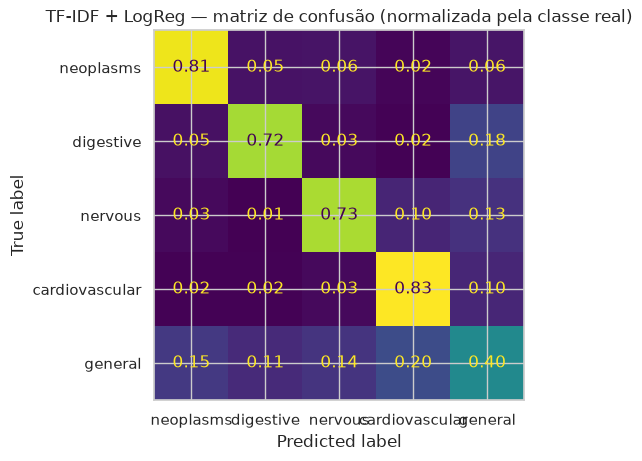

In [11]:
ConfusionMatrixDisplay.from_predictions(
    va["condition_label"],
    predicoes["tfidf_logreg"],
    labels=ORDEM,
    normalize="true",
    display_labels=[NOMES[c].split()[0] for c in ORDEM],
    values_format=".2f",
    colorbar=False,
)
plt.title("TF-IDF + LogReg — matriz de confusão (normalizada pela classe real)")
plt.show()

### Latência do baseline

In [13]:
textos_va = va["medical_abstract"].tolist()
for texto in textos_va[:30]:
    logreg.predict([texto])
tempos_ms = []
for texto in textos_va[30:330]:
    t0 = time.perf_counter()
    logreg.predict([texto])
    tempos_ms.append((time.perf_counter() - t0) * 1000)
display(
    pd.Series(np.percentile(tempos_ms, [50, 95, 99]), index=["p50_ms", "p95_ms", "p99_ms"])
    .round(2)
    .to_frame("tfidf_logreg")
    .T
)

,p50_ms,p95_ms,p99_ms
tfidf_logreg,0.55,0.66,0.69
